In [7]:
!pip install fastf1 matplotlib pandas numpy

In [8]:
# ============================================================
# F1 Telemetry Explorer - Stage 1
# Load the 2023 Bahrain Grand Prix qualifying session
# ============================================================

import os                 # lets us create folders
import fastf1             # the library that downloads F1 data
import pandas as pd       # used to build and tidy up tables

# ---------- Settings (easy to change in later stages) ----------
CACHE_FOLDER = "/content/fastf1_cache"   # where downloaded data is stored
YEAR = 2022
EVENT_NAME = "Bahrain"
SESSION_CODE = "Q"                       # "Q" means Qualifying


# ---------- Small helper: make lap times readable ----------
def format_lap_time(lap_time):
    """Turn a lap time into text like 1:29.708."""
    if pd.isna(lap_time):                # pd.isna checks for a missing value
        return "No time"
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"  # e.g. 1:29.708


# ---------- Main code: wrapped in try/except to catch errors ----------
try:
    # Create the cache folder (if needed) and tell FastF1 to use it
    os.makedirs(CACHE_FOLDER, exist_ok=True)
    fastf1.Cache.configure(cache_dir=CACHE_FOLDER)

    # Choose the session, then download/load its data
    session = fastf1.get_session(YEAR, EVENT_NAME, SESSION_CODE)
    print("Loading session data... the first run can take a minute or two.")
    session.load(
    laps=True,
    telemetry=False,
    weather=False,
    messages=False
)

    # Show the event and session names
    event_name = session.event["EventName"]
    session_name = session.name
    print(f"\nEvent:   {event_name}")
    print(f"Session: {session_name}")

    # All laps from the session (a table with one row per lap)
    all_laps = session.laps

    if all_laps is None or len(all_laps) == 0:
        print("\nNo lap data was found for this session.")
    else:
        # Keep only laps that have a lap time (some laps have none)
        timed_laps = all_laps.dropna(subset=["LapTime"])

        if len(timed_laps) == 0:
            print("\nThis session loaded, but none of its laps have a lap time.")
        else:
            # Sort from quickest to slowest and keep the first ten
            fastest_ten = timed_laps.sort_values("LapTime").head(10)

            # Build a small, clean table for display
            fastest_table = pd.DataFrame({
                "Driver": fastest_ten["Driver"].values,
                "Lap Time": [format_lap_time(t) for t in fastest_ten["LapTime"]],
            })
            fastest_table.index = range(1, len(fastest_table) + 1)  # rank 1-10
            fastest_table.index.name = "Rank"

            print("\nTen fastest laps:")
            print(fastest_table.to_string())

            # List every driver abbreviation that appears in the lap data
            driver_list = sorted(all_laps["Driver"].dropna().unique())
            print(f"\nAvailable drivers ({len(driver_list)}):")
            print(", ".join(driver_list))

except Exception as error:
    print("\nSomething went wrong while loading the data.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details:    {error}")
    print("\nThings to try:")
    print("  1. Check your internet connection and run the cell again.")
    print("  2. Check the year, event name and session code spelling.")
    print("  3. If it says 'rate limit', wait a few minutes and retry.")
    print("  4. Update FastF1 with: !pip install --upgrade fastf1")

core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading session data... the first run can take a minute or two.


core           INFO 	Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']



Event:   Bahrain Grand Prix
Session: Qualifying

Ten fastest laps:
     Driver  Lap Time
Rank                 
1       LEC  1:30.558
2       VER  1:30.681
3       SAI  1:30.687
4       LEC  1:30.731
5       SAI  1:30.739
6       VER  1:30.743
7       VER  1:30.757
8       SAI  1:30.787
9       PER  1:30.921
10      LEC  1:30.932

Available drivers (20):
ALB, ALO, BOT, GAS, HAM, HUL, LAT, LEC, MAG, MSC, NOR, OCO, PER, RIC, RUS, SAI, STR, TSU, VER, ZHO


core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading laps and telemetry... the first run can take a minute or two.


req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']



Driver:            Charles Leclerc (LEC)
Fastest valid lap: lap 14, 1:30.558
Telemetry points:  697
Maximum speed:     318 km/h


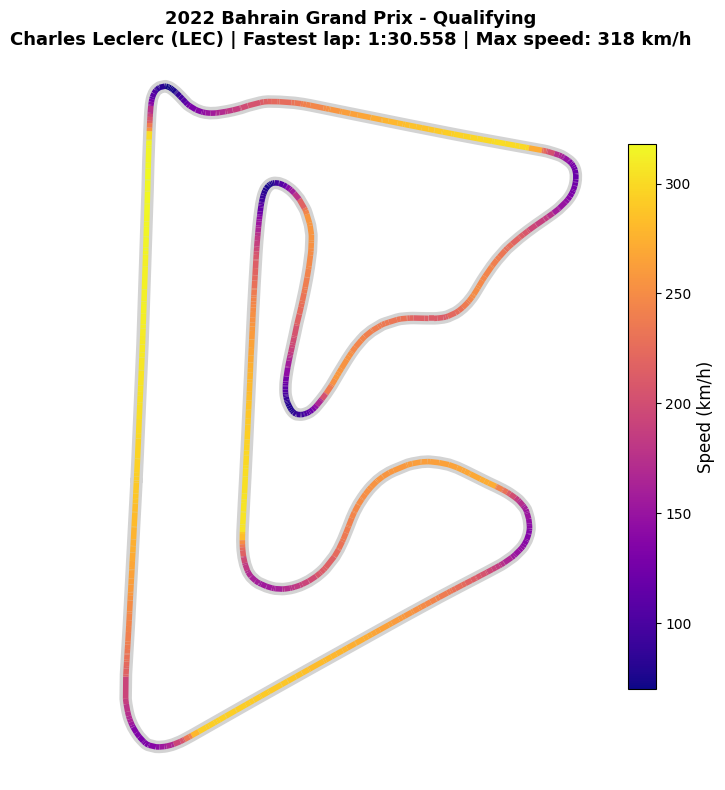

In [9]:
# ============================================================
# F1 Telemetry Explorer - Stage 2
# Circuit map of Leclerc's fastest qualifying lap, coloured by speed
# ============================================================

import os
import numpy as np                              # numbers and arrays
import pandas as pd                             # tables and data cleaning
import fastf1                                   # F1 data
import matplotlib.pyplot as plt                 # drawing the plot
from matplotlib.collections import LineCollection  # a line with many colours

# ---------- Settings (easy to change later) ----------
CACHE_FOLDER = "/content/fastf1_cache"
YEAR = 2022
EVENT_NAME = "Bahrain"
SESSION_CODE = "Q"                  # "Q" = Qualifying
DRIVER_CODE = "LEC"                 # three-letter driver abbreviation
DRIVER_NAME = "Charles Leclerc"
REQUIRED_COLUMNS = ["X", "Y", "Speed"]


# A small custom error type for problems we expect (missing data, etc.)
class DataProblem(Exception):
    """Used to show a short, clear message instead of a long traceback."""


def format_lap_time(lap_time):
    """Turn a lap time into text like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


try:
    # ---------- 1. Cache and session ----------
    os.makedirs(CACHE_FOLDER, exist_ok=True)
    fastf1.Cache.configure(cache_dir=CACHE_FOLDER)

    session = fastf1.get_session(YEAR, EVENT_NAME, SESSION_CODE)

    # Load laps AND telemetry; skip weather and race-control messages
    print("Loading laps and telemetry... the first run can take a minute or two.")
    session.load(laps=True, telemetry=True, weather=False, messages=False)

    event_name = session.event["EventName"]
    session_name = session.name

    # ---------- 2. Pick the driver's fastest valid lap ----------
    driver_laps = session.laps.pick_drivers(DRIVER_CODE)
    if driver_laps.empty:
        raise DataProblem(f"No laps were found for driver {DRIVER_CODE}.")

    # pick_fastest() ignores laps that were not counted as personal bests
    # (for example, deleted laps)
    fastest_lap = driver_laps.pick_fastest()
    if fastest_lap is None or pd.isna(fastest_lap["LapTime"]):
        raise DataProblem(f"{DRIVER_CODE} has no valid timed lap in this session.")

    lap_time_text = format_lap_time(fastest_lap["LapTime"])
    lap_number = int(fastest_lap["LapNumber"])

    # ---------- 3. Get and check the telemetry ----------
    telemetry = fastest_lap.get_telemetry()
    if telemetry is None or len(telemetry) == 0:
        raise DataProblem("This lap has no telemetry data.")

    missing_columns = [col for col in REQUIRED_COLUMNS if col not in telemetry.columns]
    if missing_columns:
        raise DataProblem(f"Telemetry is missing required columns: {missing_columns}")

    # Convert to numbers, remove infinite/missing values, keep only what we need
    clean = pd.DataFrame(
        {col: pd.to_numeric(telemetry[col], errors="coerce") for col in REQUIRED_COLUMNS}
    )
    clean = clean.replace([np.inf, -np.inf], np.nan).dropna()

    if len(clean) < 10:
        raise DataProblem(f"Only {len(clean)} usable telemetry points were found.")
    if clean["X"].nunique() < 2 or clean["Y"].nunique() < 2:
        raise DataProblem("The X/Y position data does not form a track shape.")
    if clean["Speed"].max() <= 0:
        raise DataProblem("The Speed data contains no positive values.")

    x = clean["X"].to_numpy()
    y = clean["Y"].to_numpy()
    speed = clean["Speed"].to_numpy()
    max_speed = speed.max()

    # ---------- 4. Build the coloured racing line ----------
    # Turn the points into many tiny line segments: (x1,y1) -> (x2,y2)
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    fig, ax = plt.subplots(figsize=(10, 8))

    # A wide grey line underneath gives the track an outline
    ax.plot(x, y, color="lightgrey", linewidth=9, solid_capstyle="round", zorder=1)

    # The coloured line: each segment gets a colour based on its speed
    speed_line = LineCollection(
        segments,
        cmap="plasma",
        norm=plt.Normalize(speed.min(), speed.max()),
        linewidth=4,
        zorder=2,
    )
    speed_line.set_array(speed[:-1])    # one speed value per segment
    ax.add_collection(speed_line)

    # ---------- 5. Make the plot look clean ----------
    padding = 0.05 * max(x.max() - x.min(), y.max() - y.min())
    ax.set_xlim(x.min() - padding, x.max() + padding)
    ax.set_ylim(y.min() - padding, y.max() + padding)
    ax.set_aspect("equal")              # keep the real shape of the track
    ax.axis("off")                      # hide axis numbers and box

    colorbar = fig.colorbar(speed_line, ax=ax, shrink=0.75, pad=0.02)
    colorbar.set_label("Speed (km/h)", fontsize=12)

    ax.set_title(
        f"{YEAR} {event_name} - {session_name}\n"
        f"{DRIVER_NAME} ({DRIVER_CODE}) | Fastest lap: {lap_time_text} | "
        f"Max speed: {max_speed:.0f} km/h",
        fontsize=13,
        fontweight="bold",
    )

    # Text summary printed above the plot
    print(f"\nDriver:            {DRIVER_NAME} ({DRIVER_CODE})")
    print(f"Fastest valid lap: lap {lap_number}, {lap_time_text}")
    print(f"Telemetry points:  {len(clean)}")
    print(f"Maximum speed:     {max_speed:.0f} km/h")




    plt.tight_layout()
    fig.savefig(
    "/content/f1_circuit_speed_map.png",
    dpi=200,
    bbox_inches="tight"
)

    plt.show()


except DataProblem as problem:
    print(f"\nCould not build the circuit map: {problem}")
    print("Check the driver code, event name and session code, then run the cell again.")

except Exception as error:
    print("\nSomething unexpected went wrong while loading or plotting the data.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details:    {error}")
    print("\nThings to try:")
    print("  1. Check your internet connection and run the cell again.")
    print("  2. If it mentions a rate limit, wait a few minutes and retry.")
    print("  3. Update FastF1 with: !pip install --upgrade fastf1")

core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


Loading laps and telemetry... the first run can take a minute or two.


req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']



Driver:            Charles Leclerc (LEC)
Fastest valid lap: lap 14, 1:30.558
Telemetry points:  697
Lap distance:      5362 m (from the telemetry)
Maximum speed:     318 km/h
Gears used:        2 to 8
Brake channel:     on/off signal (not brake pressure)

Figure saved to: /content/f1_telemetry_analysis.png


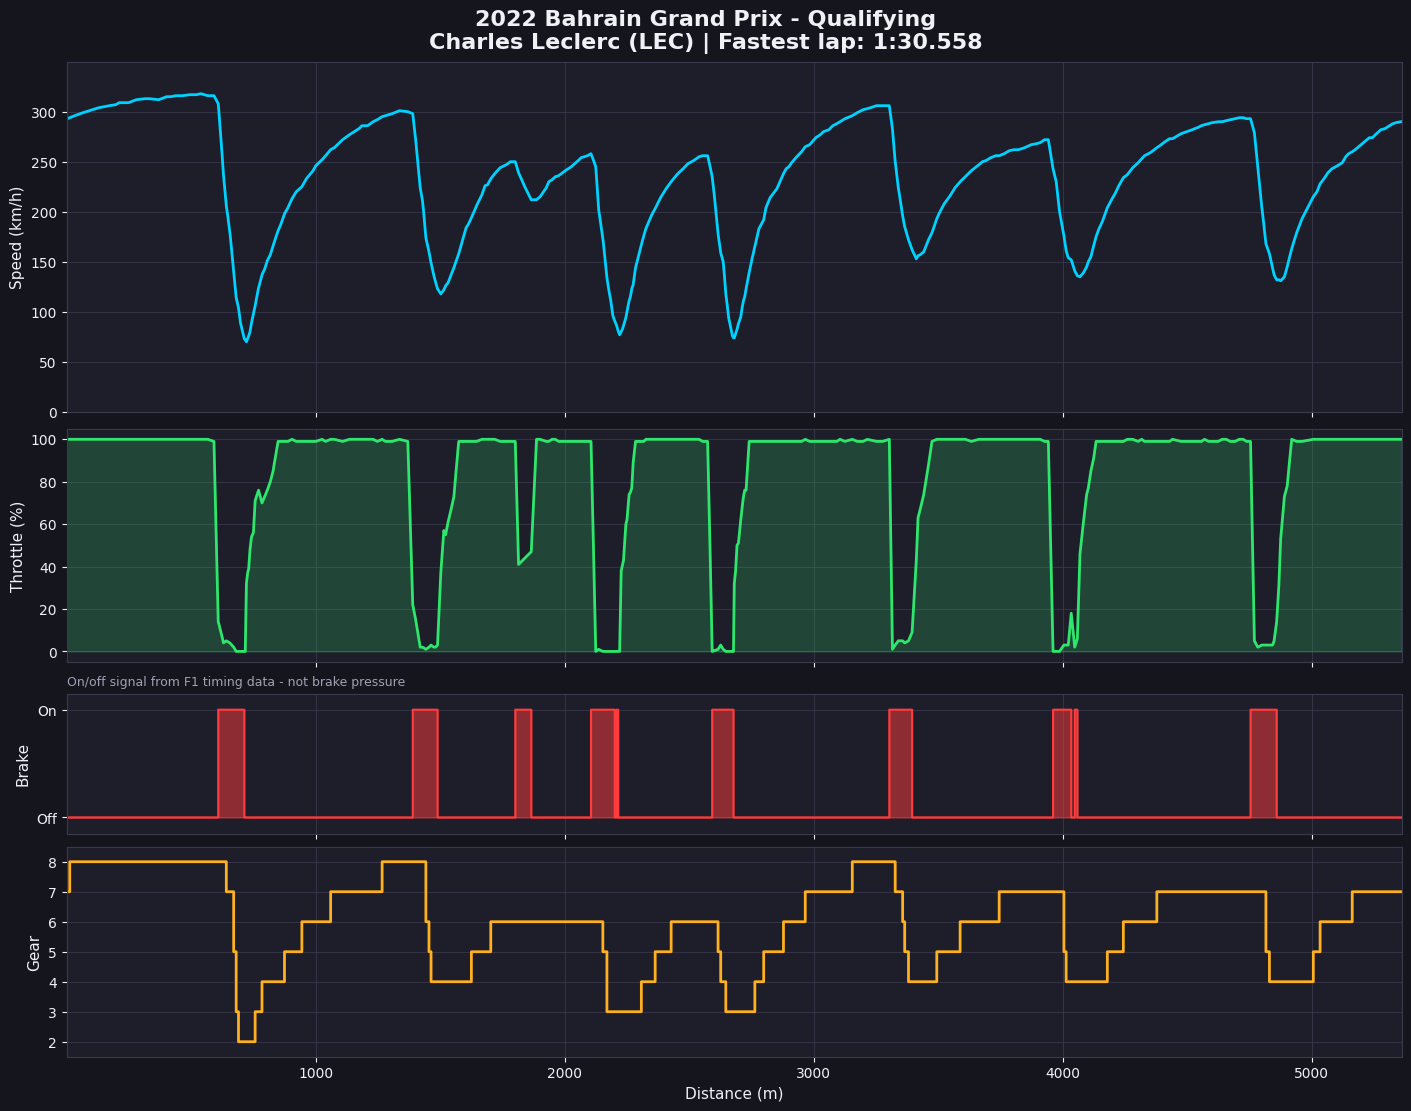

In [10]:
# ============================================================
# F1 Telemetry Explorer - Stage 3
# Speed, throttle, brake and gear traces for Leclerc's fastest lap
# ============================================================

import os
import numpy as np                       # numbers and arrays
import pandas as pd                      # tables and data cleaning
import fastf1                            # F1 data
import matplotlib.pyplot as plt          # drawing the plots

# ---------- Settings (easy to change later) ----------
CACHE_FOLDER = "/content/fastf1_cache"
YEAR = 2022
EVENT_NAME = "Bahrain"
SESSION_CODE = "Q"                       # "Q" = Qualifying
DRIVER_CODE = "LEC"                      # three-letter driver abbreviation
DRIVER_NAME = "Charles Leclerc"
OUTPUT_FILENAME = "f1_telemetry_analysis.png"
REQUIRED_COLUMNS = ["Distance", "Speed", "Throttle", "Brake", "nGear"]

# ---------- Colours for a dark, motorsport-style look ----------
BACKGROUND_COLOR = "#15151e"
PANEL_COLOR = "#1e1e2b"
GRID_COLOR = "#3a3a4d"
TEXT_COLOR = "#f0f0f5"
MUTED_COLOR = "#a0a0b5"
SPEED_COLOR = "#00d2ff"
THROTTLE_COLOR = "#2ee66b"
BRAKE_COLOR = "#ff3b3b"
GEAR_COLOR = "#ffb020"


# A small custom error type for problems we expect (missing data, etc.)
class DataProblem(Exception):
    """Used to show a short, clear message instead of a long traceback."""


def format_lap_time(lap_time):
    """Turn a lap time into text like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


def style_axis(ax, ylabel):
    """Give one panel the same dark style, grid and label."""
    ax.set_facecolor(PANEL_COLOR)
    ax.set_ylabel(ylabel, color=TEXT_COLOR, fontsize=11)
    ax.grid(True, color=GRID_COLOR, linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)                       # grid sits behind the data
    ax.tick_params(colors=TEXT_COLOR, labelsize=10)
    for spine in ax.spines.values():
        spine.set_color(GRID_COLOR)


try:
    # ---------- 1. Cache and session ----------
    os.makedirs(CACHE_FOLDER, exist_ok=True)
    fastf1.Cache.configure(cache_dir=CACHE_FOLDER)

    session = fastf1.get_session(YEAR, EVENT_NAME, SESSION_CODE)

    # Load laps AND telemetry; skip weather and race-control messages
    print("Loading laps and telemetry... the first run can take a minute or two.")
    session.load(laps=True, telemetry=True, weather=False, messages=False)

    event_name = session.event["EventName"]
    session_name = session.name

    # ---------- 2. Pick the driver's fastest valid lap ----------
    driver_laps = session.laps.pick_drivers(DRIVER_CODE)
    if driver_laps.empty:
        raise DataProblem(f"No laps were found for driver {DRIVER_CODE}.")

    # pick_fastest() ignores laps that were not counted as personal bests
    # (for example, deleted laps)
    fastest_lap = driver_laps.pick_fastest()
    if fastest_lap is None or pd.isna(fastest_lap["LapTime"]):
        raise DataProblem(f"{DRIVER_CODE} has no valid timed lap in this session.")

    lap_time_text = format_lap_time(fastest_lap["LapTime"])
    lap_number = int(fastest_lap["LapNumber"])

    # ---------- 3. Get the telemetry and check the columns ----------
    telemetry = fastest_lap.get_telemetry()
    if telemetry is None or len(telemetry) == 0:
        raise DataProblem("This lap has no telemetry data.")

    missing_columns = [col for col in REQUIRED_COLUMNS if col not in telemetry.columns]
    if missing_columns:
        raise DataProblem(f"Telemetry is missing required columns: {missing_columns}")

    # FastF1 gives Brake as True/False. Turn it into 1/0 so it can be plotted.
    brake_raw = telemetry["Brake"]
    if pd.api.types.is_bool_dtype(brake_raw):
        brake_values = brake_raw.astype(int)
    else:
        brake_values = pd.to_numeric(brake_raw, errors="coerce")

    # Convert everything to numbers, remove missing/infinite values
    clean = pd.DataFrame({
        "Distance": pd.to_numeric(telemetry["Distance"], errors="coerce"),
        "Speed": pd.to_numeric(telemetry["Speed"], errors="coerce"),
        "Throttle": pd.to_numeric(telemetry["Throttle"], errors="coerce"),
        "Brake": brake_values,
        "nGear": pd.to_numeric(telemetry["nGear"], errors="coerce"),
    })
    clean = clean.replace([np.inf, -np.inf], np.nan).dropna()

    if len(clean) < 10:
        raise DataProblem(f"Only {len(clean)} usable telemetry points were found.")
    if clean["Distance"].nunique() < 2:
        raise DataProblem("The Distance channel does not change along the lap.")
    if clean["Speed"].max() <= 0:
        raise DataProblem("The Speed data contains no positive values.")

    distance = clean["Distance"].to_numpy()
    speed = clean["Speed"].to_numpy()
    throttle = clean["Throttle"].to_numpy()
    brake = clean["Brake"].to_numpy()
    gear = clean["nGear"].to_numpy()

    # Is Brake a simple on/off signal (only 0s and 1s)?
    brake_is_on_off = bool(np.isin(brake, [0, 1]).all())

    # ---------- 4. Create four stacked plots sharing one x-axis ----------
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 11),
        sharex=True,                                   # same distance axis
        gridspec_kw={"height_ratios": [3, 2, 1.2, 1.8]},
        constrained_layout=True,                       # automatic spacing
    )
    fig.patch.set_facecolor(BACKGROUND_COLOR)
    speed_ax, throttle_ax, brake_ax, gear_ax = axes

    # Panel 1: Speed
    speed_ax.plot(distance, speed, color=SPEED_COLOR, linewidth=2)
    style_axis(speed_ax, "Speed (km/h)")
    speed_ax.set_ylim(0, speed.max() * 1.1)

    # Panel 2: Throttle
    throttle_ax.plot(distance, throttle, color=THROTTLE_COLOR, linewidth=2)
    throttle_ax.fill_between(distance, throttle, color=THROTTLE_COLOR, alpha=0.2)
    style_axis(throttle_ax, "Throttle (%)")
    throttle_ax.set_ylim(-5, max(105, throttle.max() + 5))

    # Panel 3: Brake (an on/off signal, NOT brake pressure)
    if brake_is_on_off:
        brake_ax.step(distance, brake, where="post", color=BRAKE_COLOR, linewidth=1.5)
        brake_ax.fill_between(distance, brake, step="post", color=BRAKE_COLOR, alpha=0.5)
        style_axis(brake_ax, "Brake")
        brake_ax.set_ylim(-0.15, 1.15)
        brake_ax.set_yticks([0, 1])
        brake_ax.set_yticklabels(["Off", "On"])
        brake_ax.set_title(
            "On/off signal from F1 timing data - not brake pressure",
            loc="left", fontsize=9, color=MUTED_COLOR,
        )
    else:
        # Unexpected values: plot them as they are and say so honestly
        brake_ax.plot(distance, brake, color=BRAKE_COLOR, linewidth=1.5)
        style_axis(brake_ax, "Brake (raw value)")
        brake_ax.set_title(
            "Raw Brake channel values - meaning not confirmed",
            loc="left", fontsize=9, color=MUTED_COLOR,
        )

    # Panel 4: Gear (a step plot, because gears jump from one value to the next)
    gear_ax.step(distance, gear, where="post", color=GEAR_COLOR, linewidth=2)
    style_axis(gear_ax, "Gear")
    gear_low, gear_high = int(gear.min()), int(gear.max())
    gear_ax.set_yticks(np.arange(gear_low, gear_high + 1))
    gear_ax.set_ylim(gear_low - 0.5, gear_high + 0.5)

    # Shared x-axis: label it once, on the bottom panel
    gear_ax.set_xlim(distance.min(), distance.max())
    gear_ax.set_xlabel("Distance (m)", color=TEXT_COLOR, fontsize=11)

    # Figure title with driver name and lap time
    fig.suptitle(
        f"{YEAR} {event_name} - {session_name}\n"
        f"{DRIVER_NAME} ({DRIVER_CODE}) | Fastest lap: {lap_time_text}",
        color=TEXT_COLOR, fontsize=16, fontweight="bold",
    )

    # ---------- 5. Print a summary, save the figure, show it ----------
    print(f"\nDriver:            {DRIVER_NAME} ({DRIVER_CODE})")
    print(f"Fastest valid lap: lap {lap_number}, {lap_time_text}")
    print(f"Telemetry points:  {len(clean)}")
    print(f"Lap distance:      {distance.max():.0f} m (from the telemetry)")
    print(f"Maximum speed:     {speed.max():.0f} km/h")
    print(f"Gears used:        {gear_low} to {gear_high}")
    if brake_is_on_off:
        print("Brake channel:     on/off signal (not brake pressure)")
    else:
        print("Brake channel:     unexpected values, plotted as raw numbers")

    output_path = os.path.abspath(OUTPUT_FILENAME)      # full path of the file
    fig.savefig(output_path, dpi=200, facecolor=fig.get_facecolor())

    if not os.path.exists(output_path):
        raise DataProblem("The figure could not be saved.")
    print(f"\nFigure saved to: {output_path}")

    plt.show()

except DataProblem as problem:
    print(f"\nCould not build the telemetry plots: {problem}")
    print("Check the driver code, event name and session code, then run the cell again.")

except Exception as error:
    print("\nSomething unexpected went wrong while loading, plotting or saving.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details:    {error}")
    print("\nThings to try:")
    print("  1. Check your internet connection and run the cell again.")
    print("  2. If it mentions a rate limit, wait a few minutes and retry.")
    print("  3. Update FastF1 with: !pip install --upgrade fastf1")

core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info
INFO:fastf1.fastf1.req:Using cached data for session_info
req            INFO 	Using cached data for driver_info
INFO:fastf1.fastf1.req:Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
INFO:fastf1.fastf1.req:Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
INFO:fastf1.fastf1.req:Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
INFO:fastf1.fastf1.req:Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
INFO:fastf1.fastf1.req:Using cached data for timing_app_data
core           INFO 	Processing timing data...
INFO:fastf1.fastf1.core:Processing timing data...


FastF1 version: 3.9.0
Loading laps and telemetry... the first run can take a minute or two.


req            INFO 	Using cached data for car_data
INFO:fastf1.fastf1.req:Using cached data for car_data
req            INFO 	Using cached data for position_data
INFO:fastf1.fastf1.req:Using cached data for position_data
core           INFO 	Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']
INFO:fastf1.fastf1.core:Finished loading data for 20 drivers: ['16', '1', '55', '11', '44', '77', '20', '14', '63', '10', '31', '47', '4', '23', '24', '22', '27', '3', '18', '6']



Charles Leclerc (LEC): 1:30.558 (lap 14)
Max Verstappen (VER): 1:30.681 (lap 13)
Official lap-time difference (VER - LEC): +0.123 s -> Charles Leclerc was faster
Estimated gap at the end of the common distance range: +0.310 s (telemetry estimate only)
Common distance range: 0 m to 5347 m

Figure saved to: /content/f1_driver_comparison.png


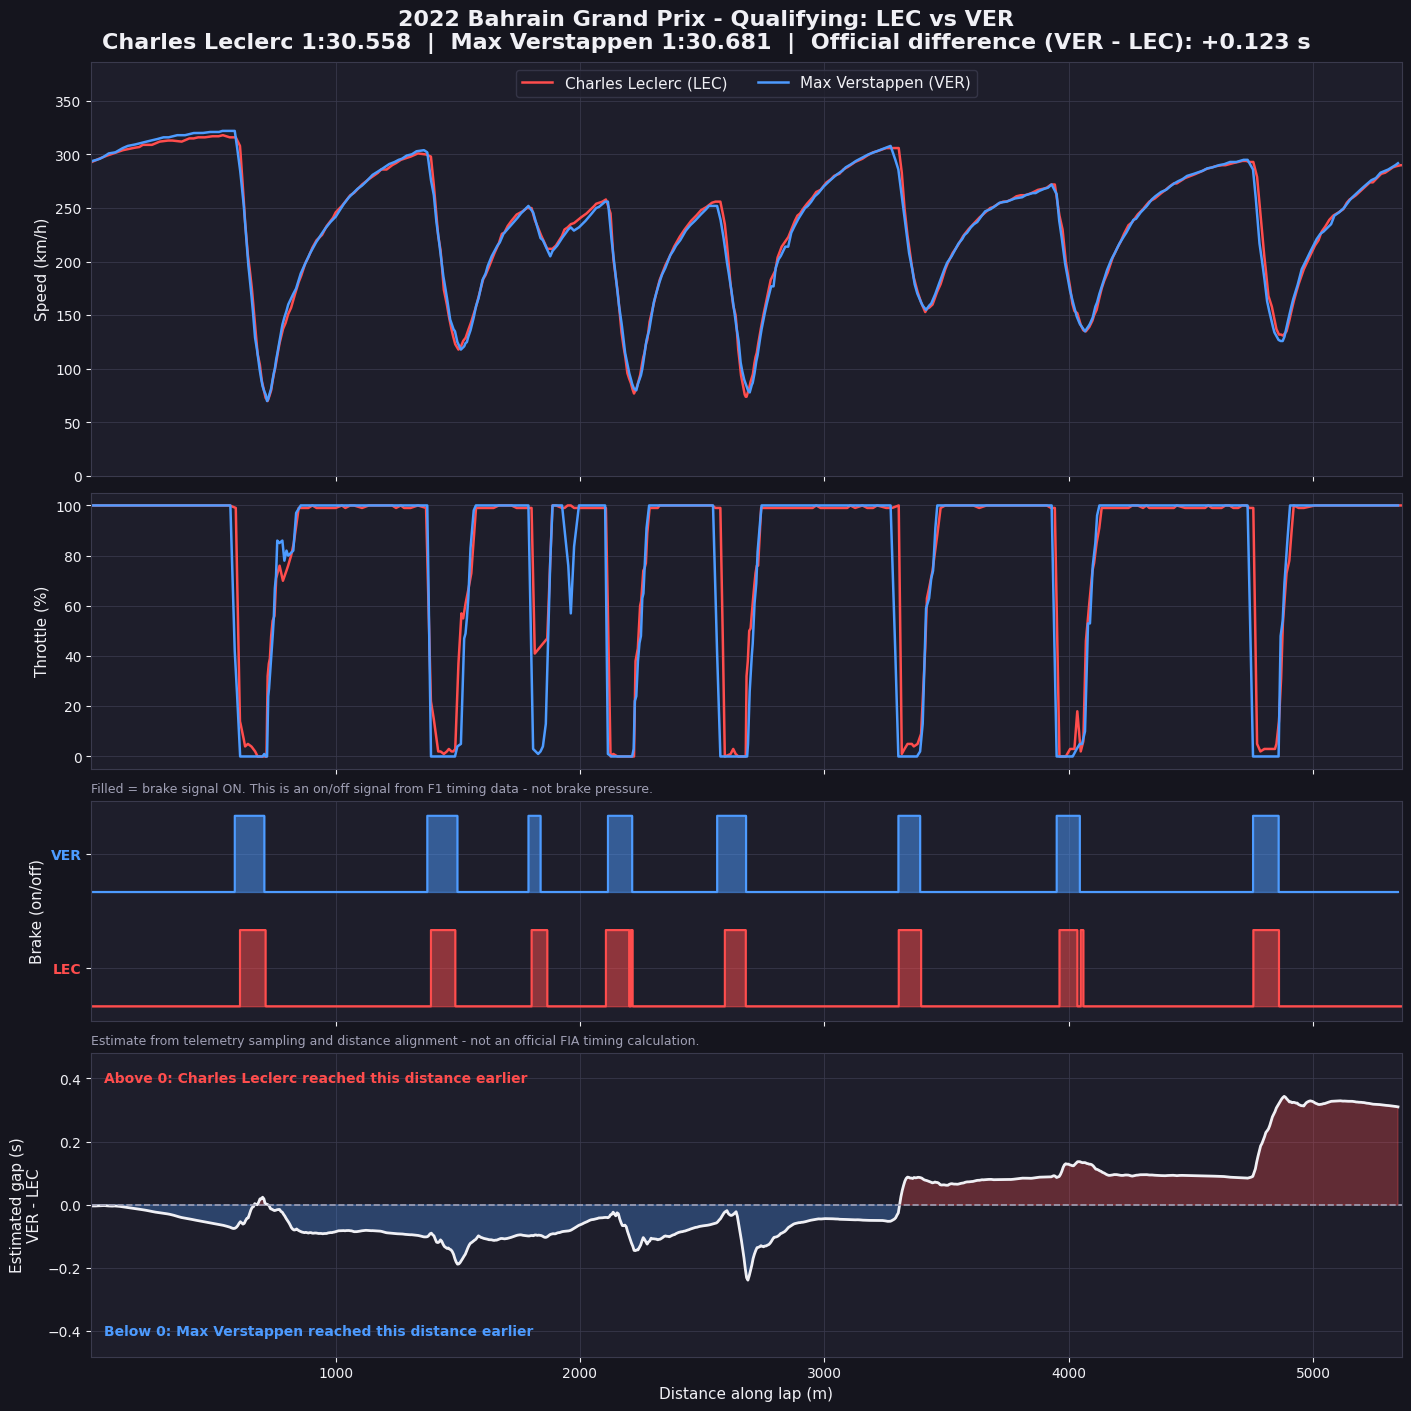

In [11]:
# ============================================================
# F1 Telemetry Explorer - Stage 4
# Compare Leclerc (LEC) and Verstappen (VER): fastest qualifying laps
# ============================================================

import os
import numpy as np                       # numbers, arrays, interpolation
import pandas as pd                      # tables and data cleaning
import fastf1                            # F1 data
import matplotlib.pyplot as plt          # drawing the plots

# ---------- Settings (easy to change later) ----------
CACHE_FOLDER = "/content/fastf1_cache"
YEAR = 2022
EVENT_NAME = "Bahrain"
SESSION_CODE = "Q"                       # "Q" = Qualifying
OUTPUT_FILENAME = "f1_driver_comparison.png"
GRID_POINTS = 1000                       # points on the common distance grid

LEC_CODE, LEC_NAME = "LEC", "Charles Leclerc"
VER_CODE, VER_NAME = "VER", "Max Verstappen"

# Columns we need from each driver's telemetry
REQUIRED_COLUMNS = ["Distance", "Speed", "Throttle", "Brake", "Time"]

# ---------- Colours for a dark, motorsport-style look ----------
BACKGROUND_COLOR = "#15151e"
PANEL_COLOR = "#1e1e2b"
GRID_COLOR = "#3a3a4d"
TEXT_COLOR = "#f0f0f5"
MUTED_COLOR = "#a0a0b5"
LEC_COLOR = "#ff4d4d"                    # Leclerc: red
VER_COLOR = "#4d9bff"                    # Verstappen: blue
GAP_COLOR = "#f0f0f5"


# A small custom error type for problems we expect (missing data, etc.)
class DataProblem(Exception):
    """Used to show a short, clear message instead of a long traceback."""


def format_lap_time(lap_time):
    """Turn a lap time into text like 1:30.558."""
    total_seconds = lap_time.total_seconds()
    minutes = int(total_seconds // 60)
    seconds = total_seconds - minutes * 60
    return f"{minutes}:{seconds:06.3f}"


def get_fastest_valid_lap(session, driver_code):
    """Return one driver's fastest valid lap, or raise a clear error."""
    driver_laps = session.laps.pick_drivers(driver_code)
    if driver_laps.empty:
        raise DataProblem(f"No laps were found for driver {driver_code}.")

    # pick_fastest() ignores laps that were not counted as personal bests
    # (for example, deleted laps)
    lap = driver_laps.pick_fastest()
    if lap is None or pd.isna(lap["LapTime"]):
        raise DataProblem(f"{driver_code} has no valid timed lap in this session.")
    return lap


def prepare_driver_data(telemetry, driver_code):
    """Check one driver's telemetry and return a clean table sorted by distance."""
    if telemetry is None or len(telemetry) == 0:
        raise DataProblem(f"{driver_code}: this lap has no telemetry data.")

    missing = [col for col in REQUIRED_COLUMNS if col not in telemetry.columns]
    if missing:
        raise DataProblem(f"{driver_code}: telemetry is missing columns: {missing}")

    # FastF1 gives Brake as True/False. Turn it into 1/0 so it can be plotted.
    brake_raw = telemetry["Brake"]
    if pd.api.types.is_bool_dtype(brake_raw):
        brake_values = brake_raw.astype(int)
    else:
        brake_values = pd.to_numeric(brake_raw, errors="coerce")

    # Elapsed seconds = Time minus this driver's FIRST telemetry sample
    time_values = pd.to_timedelta(telemetry["Time"], errors="coerce")
    elapsed_seconds = (time_values - time_values.iloc[0]).dt.total_seconds()

    table = pd.DataFrame({
        "Distance": pd.to_numeric(telemetry["Distance"], errors="coerce").to_numpy(),
        "Speed": pd.to_numeric(telemetry["Speed"], errors="coerce").to_numpy(),
        "Throttle": pd.to_numeric(telemetry["Throttle"], errors="coerce").to_numpy(),
        "Brake": pd.to_numeric(brake_values, errors="coerce").to_numpy(),
        "ElapsedSeconds": elapsed_seconds.to_numpy(),
    })

    # Remove rows with missing or infinite values
    table = table.replace([np.inf, -np.inf], np.nan).dropna()
    if len(table) < 10:
        raise DataProblem(f"{driver_code}: only {len(table)} usable telemetry rows.")

    # Sort by distance, then merge rows that share the same distance
    table = table.sort_values("Distance")
    table = table.groupby("Distance", as_index=False).agg({
        "Speed": "mean",
        "Throttle": "mean",
        "Brake": "max",                  # brake counts as ON if any row is ON
        "ElapsedSeconds": "mean",
    })

    if len(table) < 10 or table["Distance"].max() <= table["Distance"].min():
        raise DataProblem(f"{driver_code}: Distance does not change along the lap.")
    if table["Speed"].max() <= 0:
        raise DataProblem(f"{driver_code}: Speed contains no positive values.")
    if table["ElapsedSeconds"].max() <= 0:
        raise DataProblem(f"{driver_code}: Time does not increase along the lap.")
    if not np.isin(table["Brake"], [0, 1]).all():
        raise DataProblem(f"{driver_code}: Brake has unexpected values (expected on/off).")

    return table


def style_axis(ax, ylabel):
    """Give one panel the same dark style, grid and label."""
    ax.set_facecolor(PANEL_COLOR)
    ax.set_ylabel(ylabel, color=TEXT_COLOR, fontsize=11)
    ax.grid(True, color=GRID_COLOR, linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_COLOR, labelsize=10)
    for spine in ax.spines.values():
        spine.set_color(GRID_COLOR)


try:
    print(f"FastF1 version: {fastf1.__version__}")

    # ---------- 1. Cache and session ----------
    if not hasattr(fastf1.Cache, "configure"):
        raise DataProblem(
            "This FastF1 version has no Cache.configure (needs 3.9.0 or newer). "
            "Upgrade with: !pip install --upgrade fastf1  "
            "then use Runtime > Restart session and run this cell again."
        )
    os.makedirs(CACHE_FOLDER, exist_ok=True)
    fastf1.Cache.configure(cache_dir=CACHE_FOLDER)

    session = fastf1.get_session(YEAR, EVENT_NAME, SESSION_CODE)

    # Load laps AND telemetry; skip weather and race-control messages
    print("Loading laps and telemetry... the first run can take a minute or two.")
    session.load(laps=True, telemetry=True, weather=False, messages=False)

    event_name = session.event["EventName"]
    session_name = session.name

    # ---------- 2. Fastest valid lap for each driver ----------
    lec_lap = get_fastest_valid_lap(session, LEC_CODE)
    ver_lap = get_fastest_valid_lap(session, VER_CODE)

    lec_seconds = lec_lap["LapTime"].total_seconds()
    ver_seconds = ver_lap["LapTime"].total_seconds()
    lec_time_text = format_lap_time(lec_lap["LapTime"])
    ver_time_text = format_lap_time(ver_lap["LapTime"])
    lap_difference = ver_seconds - lec_seconds      # official: VER minus LEC

    # ---------- 3. Telemetry: check, clean and sort ----------
    lec = prepare_driver_data(lec_lap.get_telemetry(), LEC_CODE)
    ver = prepare_driver_data(ver_lap.get_telemetry(), VER_CODE)

    # ---------- 4. Estimate the time gap along the lap ----------
    # Both drivers get a common set of distance points (up to the shorter lap),
    # then each driver's elapsed time is interpolated onto those points.
    grid_start = max(lec["Distance"].min(), ver["Distance"].min())
    grid_end = min(lec["Distance"].max(), ver["Distance"].max())
    if grid_end - grid_start < 100:
        raise DataProblem("The two laps share too little distance to be compared.")

    distance_grid = np.linspace(grid_start, grid_end, GRID_POINTS)
    lec_elapsed = np.interp(distance_grid, lec["Distance"], lec["ElapsedSeconds"])
    ver_elapsed = np.interp(distance_grid, ver["Distance"], ver["ElapsedSeconds"])

    # Positive: VER needed more time to reach this point -> LEC was there earlier
    time_gap = ver_elapsed - lec_elapsed
    if not np.isfinite(time_gap).all():
        raise DataProblem("The time-gap calculation produced invalid numbers.")

    # ---------- 5. Build the four stacked panels ----------
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 14),
        sharex=True,                                   # one shared distance axis
        gridspec_kw={"height_ratios": [3, 2, 1.6, 2.2]},
        constrained_layout=True,
    )
    fig.patch.set_facecolor(BACKGROUND_COLOR)
    speed_ax, throttle_ax, brake_ax, gap_ax = axes

    # Panel 1: Speed
    speed_ax.plot(lec["Distance"], lec["Speed"], color=LEC_COLOR, linewidth=1.8, label=f"{LEC_NAME} ({LEC_CODE})")
    speed_ax.plot(ver["Distance"], ver["Speed"], color=VER_COLOR, linewidth=1.8, label=f"{VER_NAME} ({VER_CODE})")
    style_axis(speed_ax, "Speed (km/h)")
    top_speed = max(lec["Speed"].max(), ver["Speed"].max())
    speed_ax.set_ylim(0, top_speed * 1.2)              # extra room for the legend
    speed_ax.legend(loc="upper center", ncol=2, facecolor=PANEL_COLOR,
                    edgecolor=GRID_COLOR, labelcolor=TEXT_COLOR, fontsize=11)

    # Panel 2: Throttle
    throttle_ax.plot(lec["Distance"], lec["Throttle"], color=LEC_COLOR, linewidth=1.8)
    throttle_ax.plot(ver["Distance"], ver["Throttle"], color=VER_COLOR, linewidth=1.8)
    style_axis(throttle_ax, "Throttle (%)")
    throttle_ax.set_ylim(-5, 105)

    # Panel 3: Brake - one "lane" per driver so the two signals don't overlap
    lec_lane, ver_lane = 0.0, 1.5
    for data, lane, colour in [(lec, lec_lane, LEC_COLOR), (ver, ver_lane, VER_COLOR)]:
        brake_line = data["Brake"].to_numpy() + lane
        brake_ax.step(data["Distance"], brake_line, where="post", color=colour, linewidth=1.5)
        brake_ax.fill_between(data["Distance"], lane, brake_line, step="post",
                              color=colour, alpha=0.5)
    style_axis(brake_ax, "Brake (on/off)")
    brake_ax.set_ylim(-0.2, 2.7)
    brake_ax.set_yticks([lec_lane + 0.5, ver_lane + 0.5])
    brake_ax.set_yticklabels([LEC_CODE, VER_CODE])
    for label, colour in zip(brake_ax.get_yticklabels(), [LEC_COLOR, VER_COLOR]):
        label.set_color(colour)
        label.set_fontweight("bold")
    brake_ax.set_title(
        "Filled = brake signal ON. This is an on/off signal from F1 timing data - not brake pressure.",
        loc="left", fontsize=9, color=MUTED_COLOR,
    )

    # Panel 4: Estimated time gap
    gap_ax.plot(distance_grid, time_gap, color=GAP_COLOR, linewidth=2)
    gap_ax.fill_between(distance_grid, time_gap, 0, where=time_gap >= 0,
                        interpolate=True, color=LEC_COLOR, alpha=0.3)
    gap_ax.fill_between(distance_grid, time_gap, 0, where=time_gap < 0,
                        interpolate=True, color=VER_COLOR, alpha=0.3)
    gap_ax.axhline(0, color=MUTED_COLOR, linestyle="--", linewidth=1.2)   # zero reference
    style_axis(gap_ax, f"Estimated gap (s)\n{VER_CODE} - {LEC_CODE}")
    gap_limit = max(np.abs(time_gap).max() * 1.4, 0.05)
    gap_ax.set_ylim(-gap_limit, gap_limit)
    gap_ax.text(0.01, 0.94, f"Above 0: {LEC_NAME} reached this distance earlier",
                transform=gap_ax.transAxes, color=LEC_COLOR, fontsize=10,
                fontweight="bold", va="top")
    gap_ax.text(0.01, 0.06, f"Below 0: {VER_NAME} reached this distance earlier",
                transform=gap_ax.transAxes, color=VER_COLOR, fontsize=10,
                fontweight="bold", va="bottom")
    gap_ax.set_title(
        "Estimate from telemetry sampling and distance alignment - not an official FIA timing calculation.",
        loc="left", fontsize=9, color=MUTED_COLOR,
    )

    # Shared x-axis, labelled once on the bottom panel
    gap_ax.set_xlim(min(lec["Distance"].min(), ver["Distance"].min()),
                    max(lec["Distance"].max(), ver["Distance"].max()))
    gap_ax.set_xlabel("Distance along lap (m)", color=TEXT_COLOR, fontsize=11)

    fig.suptitle(
        f"{YEAR} {event_name} - {session_name}: {LEC_CODE} vs {VER_CODE}\n"
        f"{LEC_NAME} {lec_time_text}  |  {VER_NAME} {ver_time_text}  |  "
        f"Official difference ({VER_CODE} - {LEC_CODE}): {lap_difference:+.3f} s",
        color=TEXT_COLOR, fontsize=16, fontweight="bold",
    )

    # ---------- 6. Print the summary, save the figure, show it ----------
    if lap_difference > 0:
        faster_text = f"{LEC_NAME} was faster"
    elif lap_difference < 0:
        faster_text = f"{VER_NAME} was faster"
    else:
        faster_text = "the lap times were identical"

    print(f"\n{LEC_NAME} ({LEC_CODE}): {lec_time_text} (lap {int(lec_lap['LapNumber'])})")
    print(f"{VER_NAME} ({VER_CODE}): {ver_time_text} (lap {int(ver_lap['LapNumber'])})")
    print(f"Official lap-time difference ({VER_CODE} - {LEC_CODE}): "
          f"{lap_difference:+.3f} s -> {faster_text}")
    print(f"Estimated gap at the end of the common distance range: {time_gap[-1]:+.3f} s "
          f"(telemetry estimate only)")
    print(f"Common distance range: {grid_start:.0f} m to {grid_end:.0f} m")

    output_path = os.path.abspath(OUTPUT_FILENAME)
    fig.savefig(output_path, dpi=200, facecolor=fig.get_facecolor())
    if not os.path.exists(output_path):
        raise DataProblem("The figure could not be saved.")
    print(f"\nFigure saved to: {output_path}")

    plt.show()

except DataProblem as problem:
    print(f"\nCould not build the driver comparison: {problem}")

except Exception as error:
    print("\nSomething unexpected went wrong while loading, plotting or saving.")
    print(f"Error type: {type(error).__name__}")
    print(f"Details:    {error}")
    print("\nThings to try:")
    print("  1. Check your internet connection and run the cell again.")
    print("  2. Make sure FastF1 is 3.9.0 or newer: !pip install --upgrade fastf1")
    print("  3. If the message mentions login, authentication, 401 or 403, Formula 1 may")
    print("     now require an F1TV sign-in to download session data that is not cached.")
    print("  4. If it mentions a rate limit, wait a few minutes and retry.")

In [14]:
import os

output_files = [
    "/content/f1_circuit_speed_map.png",
    "/content/f1_telemetry_analysis.png",
    "/content/f1_driver_comparison.png"
]

for file in output_files:
    if os.path.exists(file):
        print("✅ FOUND:", os.path.basename(file))
    else:
        print("❌ MISSING:", os.path.basename(file))

✅ FOUND: f1_circuit_speed_map.png
✅ FOUND: f1_telemetry_analysis.png
✅ FOUND: f1_driver_comparison.png


In [15]:
import zipfile
from google.colab import files
import os

output_files = [
    "/content/f1_circuit_speed_map.png",
    "/content/f1_telemetry_analysis.png",
    "/content/f1_driver_comparison.png"
]

zip_path = "/content/f1_telemetry_outputs.zip"

with zipfile.ZipFile(zip_path, "w") as archive:
    for file in output_files:
        archive.write(file, arcname=os.path.basename(file))

print("✅ All three graphs added to the ZIP.")
files.download(zip_path)

✅ All three graphs added to the ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>